# CV Day 1 · 실습 5. CNN Feature Map 관찰

교안 **1~5** 연계 · `assets/color_sample.png` · 사전학습 SqueezeNet 1.1

코드를 순서대로 실행하고, `★` 표시된 값을 변경하여 결과를 비교합니다.

## 1. 실습 준비 및 모델 확인
### 1.1~1.2 이미지와 실습 파일 확인

PIL size (W, H): (512, 512)
NumPy shape (H, W, C): (512, 512, 3)


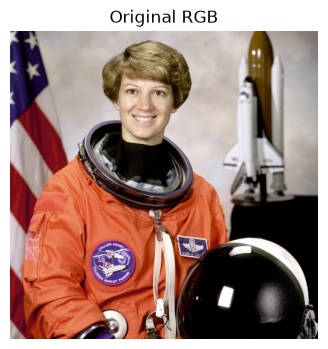

In [10]:
from pathlib import Path
import hashlib

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torchvision.models import squeezenet1_1, SqueezeNet1_1_Weights
from torchvision.transforms import functional as TF

# Notebook 실행 위치에 따라 프로젝트 폴더 탐색
candidates = [
    Path.cwd(),
    Path.cwd() / "module2_cv_nlp",
    Path.cwd().parent / "module2_cv_nlp",
]
PROJECT = next(
    (p for p in candidates if (p / "assets" / "color_sample.png").is_file()),
    None,
)
if PROJECT is None:
    raise FileNotFoundError("assets/color_sample.png 파일과 Notebook 위치를 확인하세요.")

image_path = PROJECT / "assets" / "color_sample.png"
pil_image = Image.open(image_path).convert("RGB")
original_rgb = np.asarray(pil_image)

print("PIL size (W, H):", pil_image.size)
print("NumPy shape (H, W, C):", original_rgb.shape)

plt.figure(figsize=(5, 4))
plt.imshow(original_rgb)
plt.title("Original RGB")
plt.axis("off")
plt.show()

### 1.3 사전학습 SqueezeNet 1.1 불러오기
로컬 파일 또는 캐시의 공식 가중치를 사용하며, 없으면 최초 한 번 다운로드합니다.

In [11]:
weights = SqueezeNet1_1_Weights.DEFAULT
preprocess = weights.transforms()
weight_filename = "squeezenet1_1-b8a52dc0.pth"

local_checkpoint = PROJECT / "assets" / weight_filename
cached_checkpoint = Path(torch.hub.get_dir()) / "checkpoints" / weight_filename
available_checkpoint = next(
    (p for p in (local_checkpoint, cached_checkpoint) if p.is_file()),
    None,
)

if available_checkpoint is not None:
    digest = hashlib.sha256(available_checkpoint.read_bytes()).hexdigest()
    if not digest.startswith("b8a52dc0"):
        raise ValueError(f"공식 가중치와 일치하지 않습니다: {available_checkpoint}")
    model = squeezenet1_1(weights=None)
    state_dict = torch.load(available_checkpoint, map_location="cpu", weights_only=True)
    model.load_state_dict(state_dict, strict=True)
    print("사전학습 가중치 로드:", available_checkpoint)
else:
    try:
        model = squeezenet1_1(weights=weights)
        print("공식 사전학습 가중치 다운로드 및 로드 완료")
    except Exception as exc:
        raise RuntimeError(
            f"가중치를 불러올 수 없습니다. {weight_filename} 파일을 "
            f"{PROJECT / 'assets'} 폴더에 준비하세요."
        ) from exc

model = model.cpu().eval()
print("Model: SqueezeNet 1.1 (pretrained)")

사전학습 가중치 로드: /Users/jian/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth
Model: SqueezeNet 1.1 (pretrained)


## 2. Sobel Filter와 CNN 초기 Feature Map 비교
### 2.1 이미지 준비하기
Sobel과 CNN이 같은 이미지 영역을 처리하도록 맞춥니다.

CNN Input (NCHW): (1, 3, 224, 224)
Sobel Input (HW): (224, 224)


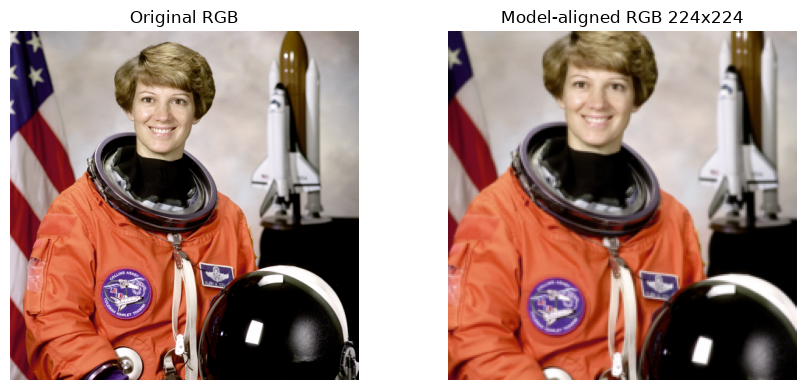

In [12]:
input_tensor = preprocess(pil_image).unsqueeze(0)
assert tuple(input_tensor.shape) == (1, 3, 224, 224)

aligned_pil = TF.center_crop(
    TF.resize(
        pil_image,
        preprocess.resize_size,
        interpolation=preprocess.interpolation,
    ),
    preprocess.crop_size,
)
aligned_rgb = np.asarray(aligned_pil)
aligned_gray = cv2.cvtColor(aligned_rgb, cv2.COLOR_RGB2GRAY)
assert aligned_rgb.shape == (224, 224, 3)

print("CNN Input (NCHW):", tuple(input_tensor.shape))
print("Sobel Input (HW):", aligned_gray.shape)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(original_rgb)
axes[0].set_title("Original RGB")
axes[1].imshow(aligned_rgb)
axes[1].set_title("Model-aligned RGB 224x224")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2.2 Sobel과 CNN 초기 Feature Map 비교하기
Sobel X/Y 및 Gradient Magnitude와 CNN의 0~3번 채널을 비교합니다.

CNN early Feature Map: (1, 64, 111, 111)


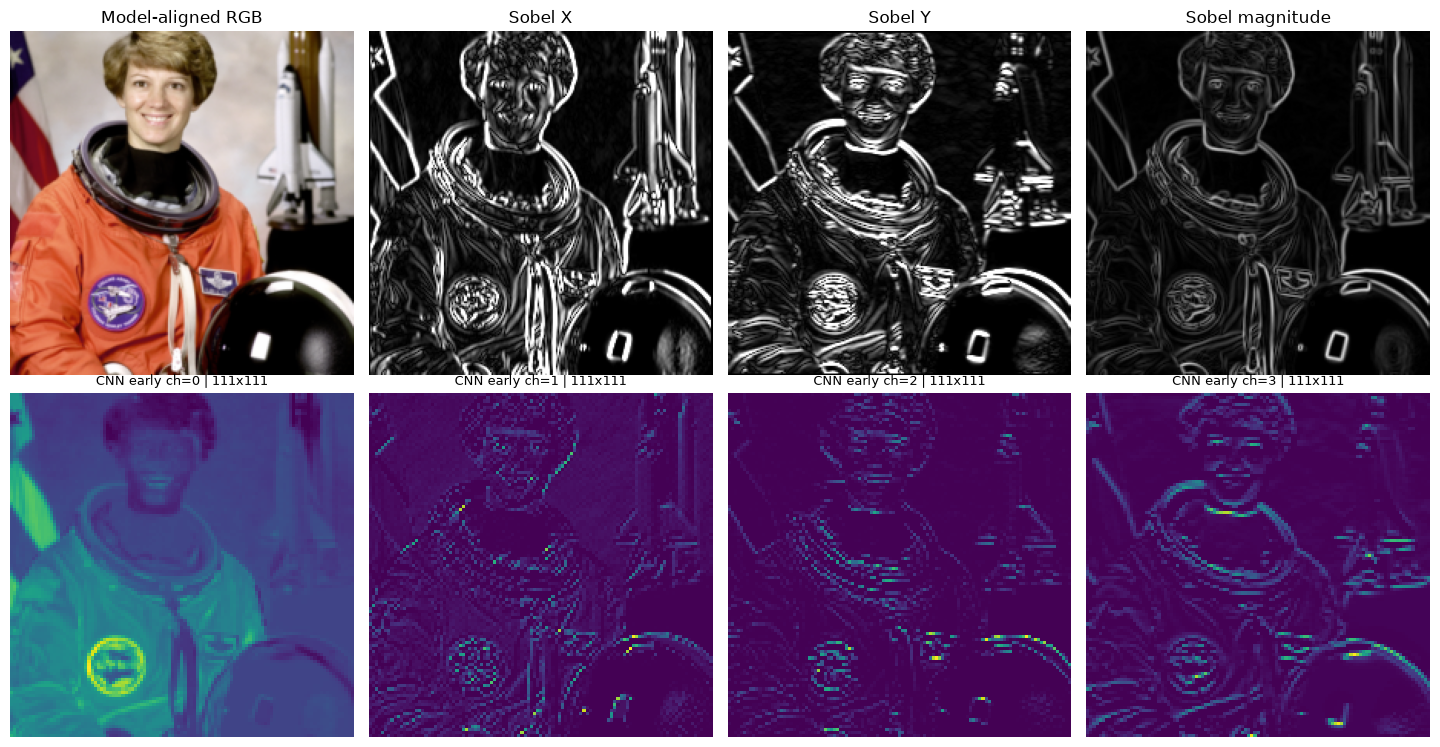

In [13]:
sobel_x = cv2.Sobel(aligned_gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(aligned_gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = np.hypot(sobel_x, sobel_y)

# 시각화용 값: X/Y의 부호를 제거하므로 원래 Gradient와 구분
sobel_x_view = cv2.convertScaleAbs(sobel_x)
sobel_y_view = cv2.convertScaleAbs(sobel_y)
sobel_mag_view = cv2.normalize(
    sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

early_holder = {}

def capture_early(module, inputs, output):
    early_holder["map"] = output.detach().cpu().clone()

handle = model.features[1].register_forward_hook(capture_early)
try:
    with torch.inference_mode():
        _ = model(input_tensor)
finally:
    handle.remove()

early_map = early_holder["map"]
assert tuple(early_map.shape) == (1, 64, 111, 111)
print("CNN early Feature Map:", tuple(early_map.shape))

# 각 채널을 별도 색상 범위로 표시: 화면 밝기만으로 채널 간 강도 비교 불가
def show_feature(ax, fmap, channel, label="CNN"):
    values = fmap[0, channel].numpy()
    vmin, vmax = float(values.min()), float(values.max())
    if vmin == vmax:
        vmax = vmin + 1e-6
    ax.imshow(
        values, cmap="viridis", vmin=vmin, vmax=vmax,
        interpolation="nearest",
    )
    ax.set_title(
        f"{label} ch={channel} | {values.shape[0]}x{values.shape[1]}",
        fontsize=9,
    )
    ax.axis("off")
    return float(values.min()), float(values.max()), float(values.mean())

fig, axes = plt.subplots(2, 4, figsize=(14.5, 7.5))
imgs = [aligned_rgb, sobel_x_view, sobel_y_view, sobel_mag_view]
titles = ["Model-aligned RGB", "Sobel X", "Sobel Y", "Sobel magnitude"]
for ax, img, title in zip(axes[0], imgs, titles):
    if img.ndim == 2:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
for ax, ch in zip(axes[1], [0, 1, 2, 3]):
    show_feature(ax, early_map, ch, "CNN early")
plt.tight_layout()
plt.show()

### 2.3 조건 변경 — 초기 Feature Map 채널 비교
★ `channel_indices`: `[0, 1, 2, 3]` → `[4, 5, 6, 7]`

채널  0: 최소=0.000, 최대=5.238, 평균=1.474
채널  1: 최소=0.000, 최대=2.750, 평균=0.116
채널  2: 최소=0.000, 최대=5.716, 평균=0.138
채널  3: 최소=0.000, 최대=12.714, 평균=0.515


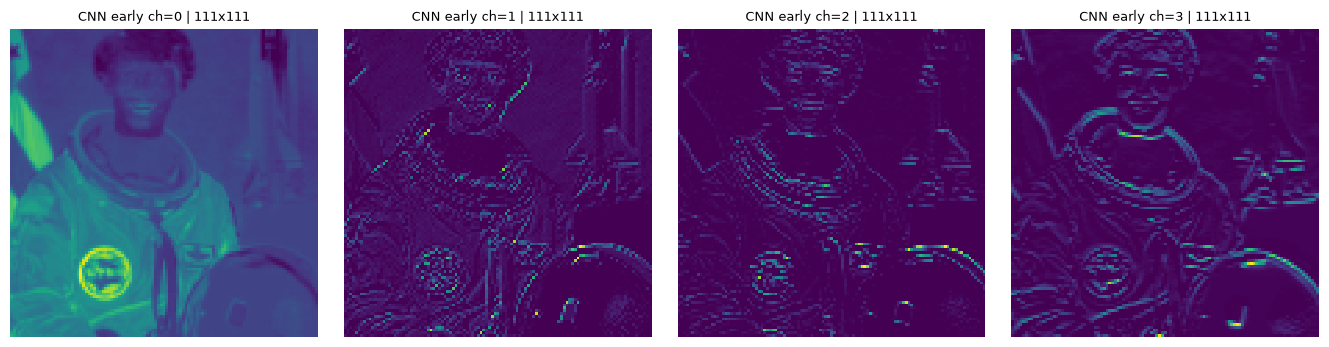

In [14]:
# ★ 변경할 값: [0, 1, 2, 3] → [4, 5, 6, 7]
channel_indices = [0, 1, 2, 3]
assert len(channel_indices) == 4
assert all(0 <= ch < early_map.shape[1] for ch in channel_indices)

fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.4))
for ax, ch in zip(axes, channel_indices):
    minimum, maximum, mean = show_feature(ax, early_map, ch, "CNN early")
    print(f"채널 {ch:2d}: 최소={minimum:.3f}, 최대={maximum:.3f}, 평균={mean:.3f}")
plt.tight_layout()
plt.show()

## 3. Conv 설정에 따른 출력 Shape 변화
### 3.1 기본 Conv2d 실행과 출력 Shape 이해

In [15]:
shape_input = torch.zeros((1, 3, 32, 32))
conv = nn.Conv2d(3, 8, kernel_size=3, stride=1, padding=1)
with torch.inference_mode():
    output = conv(shape_input)

assert tuple(output.shape) == (1, 8, 32, 32)
print("Input:", tuple(shape_input.shape))
print("Output:", tuple(output.shape))

Input: (1, 3, 32, 32)
Output: (1, 8, 32, 32)


### 3.2 Stride·Padding 변경과 출력 Shape 비교
입력 채널 3개·출력 채널 8개·Kernel 3×3을 고정하여 비교합니다.

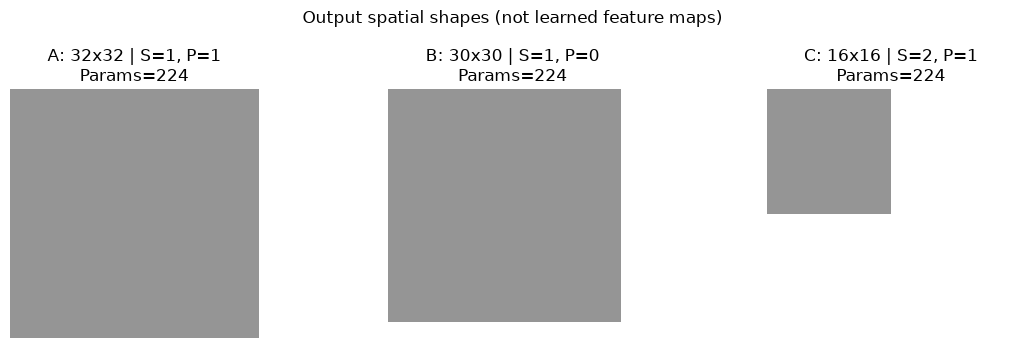

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5))

for ax, (label, k, s, p, out_shape, params) in zip(axes, shape_rows):
    h, w = out_shape[2:]

    ax.imshow(
        np.ones((h, w)),
        cmap="Greys",
        vmin=0,
        vmax=2,
        extent=(0, w, h, 0),
        interpolation="nearest"
    )

    # 세 그래프의 좌표 범위를 동일하게 설정
    ax.set_xlim(0, 32)
    ax.set_ylim(32, 0)
    ax.set_aspect("equal")

    ax.set_title(
        f"{label}: {h}x{w} | S={s}, P={p}\nParams={params}"
    )
    ax.axis("off")

fig.suptitle("Output spatial shapes (not learned feature maps)")
plt.tight_layout()
plt.show()

### 3.3 Kernel Size와 파라미터 수 비교
★ `kernel_sizes`: `[1, 3, 5]` → `[1, 3, 7]`

In [17]:
# ★ 변경할 값: [1, 3, 5] → [1, 3, 7]
kernel_sizes = [1, 3, 5]

print(f'{"Kernel":>6}  {"Output NCHW":<19} {"Params":>7}')
for k in kernel_sizes:
    conv = nn.Conv2d(3, 8, kernel_size=k, stride=1, padding=0)
    with torch.inference_mode():
        y = conv(shape_input)
    params = sum(t.numel() for t in conv.parameters())
    expected_hw = 32 - k + 1
    assert tuple(y.shape) == (1, 8, expected_hw, expected_hw)
    print(f"{k:>6}  {str(tuple(y.shape)):<19} {params:>7}")

Kernel  Output NCHW          Params
     1  (1, 8, 32, 32)           32
     3  (1, 8, 30, 30)          224
     5  (1, 8, 28, 28)          608


## 4. CNN 계층별 Feature Map 관찰
### 4.1 초기·중간·깊은 계층의 출력 추출하기
`features[1]`, `features[6]`, `features[12]`의 출력을 Forward Hook으로 저장합니다.

In [18]:
feature_maps = {}

def save_feature(name):
    def hook(module, inputs, output):
        feature_maps[name] = output.detach().cpu().clone()
    return hook

hook_layers = {"early": 1, "middle": 6, "deep": 12}
hooks = [
    model.features[idx].register_forward_hook(save_feature(name))
    for name, idx in hook_layers.items()
]
try:
    with torch.inference_mode():
        _ = model(input_tensor)
finally:
    for hook in hooks:
        hook.remove()

### 4.2 계층별 출력 Shape와 Feature Map 비교

early : NCHW (1, 64, 111, 111) | 채널=64, 공간=111x111
middle: NCHW (1, 256, 27, 27) | 채널=256, 공간=27x27
deep  : NCHW (1, 512, 13, 13) | 채널=512, 공간=13x13


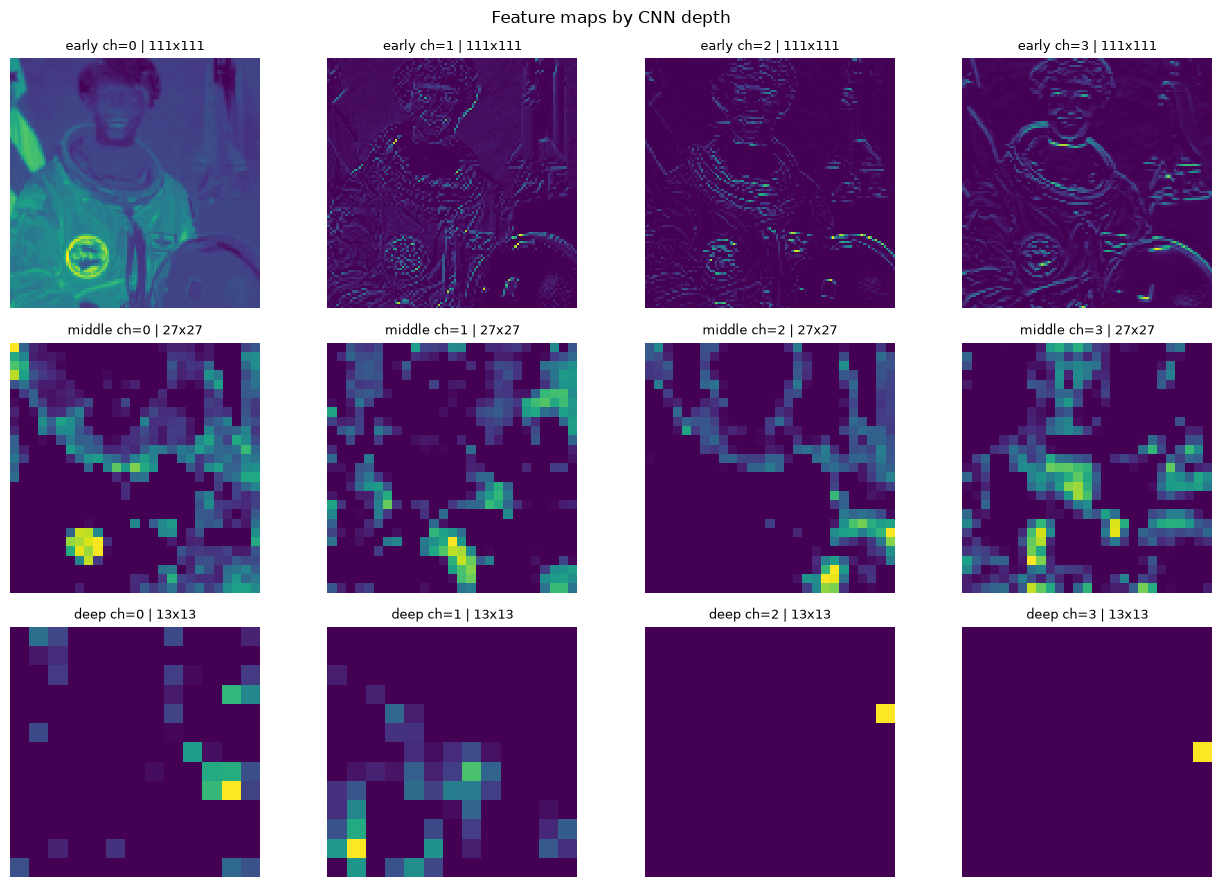

In [19]:
expected_shapes = {
    "early": (1, 64, 111, 111),
    "middle": (1, 256, 27, 27),
    "deep": (1, 512, 13, 13),
}

for name, expected in expected_shapes.items():
    fmap = feature_maps[name]
    assert tuple(fmap.shape) == expected
    print(f"{name:6s}: NCHW {expected} | 채널={expected[1]}, 공간={expected[2]}x{expected[3]}")

layers_to_show = ["early", "middle", "deep"]
fig, axes = plt.subplots(3, 4, figsize=(13, 9))
for i, layer_name in enumerate(layers_to_show):
    fmap = feature_maps[layer_name]
    for j, ch in enumerate([0, 1, 2, 3]):
        show_feature(axes[i, j], fmap, ch, layer_name)
fig.suptitle("Feature maps by CNN depth")
plt.tight_layout()
plt.show()

### 4.3 조건 변경 — 깊은 계층 채널 비교
★ `deep_channels`: `[0, 1, 2, 3]` → `[8, 16, 32, 64]`

깊은 계층 채널   0: 최소=0.0000, 최대=70.5780, 평균=3.4813
깊은 계층 채널   1: 최소=0.0000, 최대=117.7351, 평균=8.3087
깊은 계층 채널   2: 최소=0.0000, 최대=20.8886, 평균=0.1236
깊은 계층 채널   3: 최소=0.0000, 최대=10.7182, 평균=0.0634


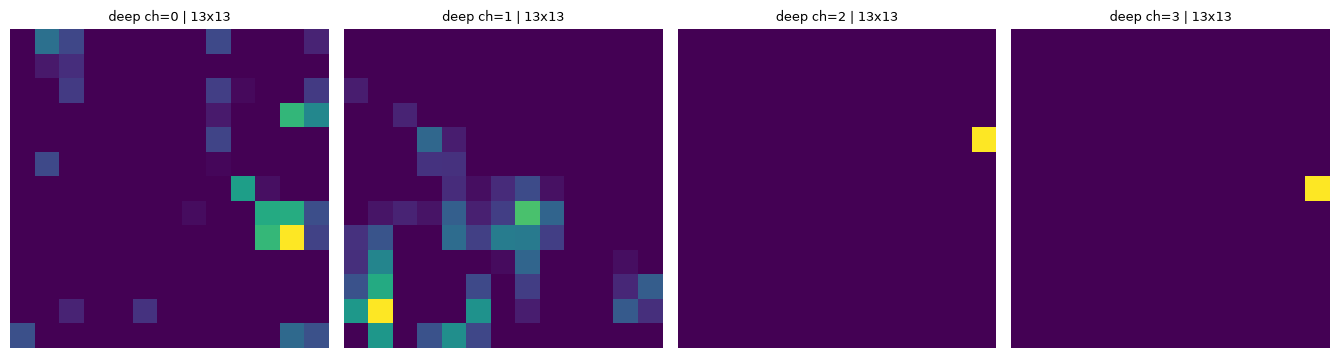

In [20]:
# ★ 변경할 값: [0, 1, 2, 3] → [8, 16, 32, 64]
deep_channels = [0, 1, 2, 3]
deep_map = feature_maps["deep"]
assert len(deep_channels) == 4
assert all(0 <= ch < deep_map.shape[1] for ch in deep_channels)

fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.5))
for ax, ch in zip(axes, deep_channels):
    minimum, maximum, mean = show_feature(ax, deep_map, ch, "deep")
    print(f"깊은 계층 채널 {ch:3d}: 최소={minimum:.4f}, 최대={maximum:.4f}, 평균={mean:.4f}")
plt.tight_layout()
plt.show()

## 5. 이번 실습 간단하게 요약
- Sobel은 고정 Kernel, CNN은 학습된 필터로 특징을 추출합니다.
- Conv 설정에 따라 출력 공간 크기가 달라지며, 파라미터 수와는 구분해야 합니다.
- 이번 SqueezeNet에서는 깊은 계층으로 갈수록 공간 크기는 줄고 채널 수는 늘어납니다.

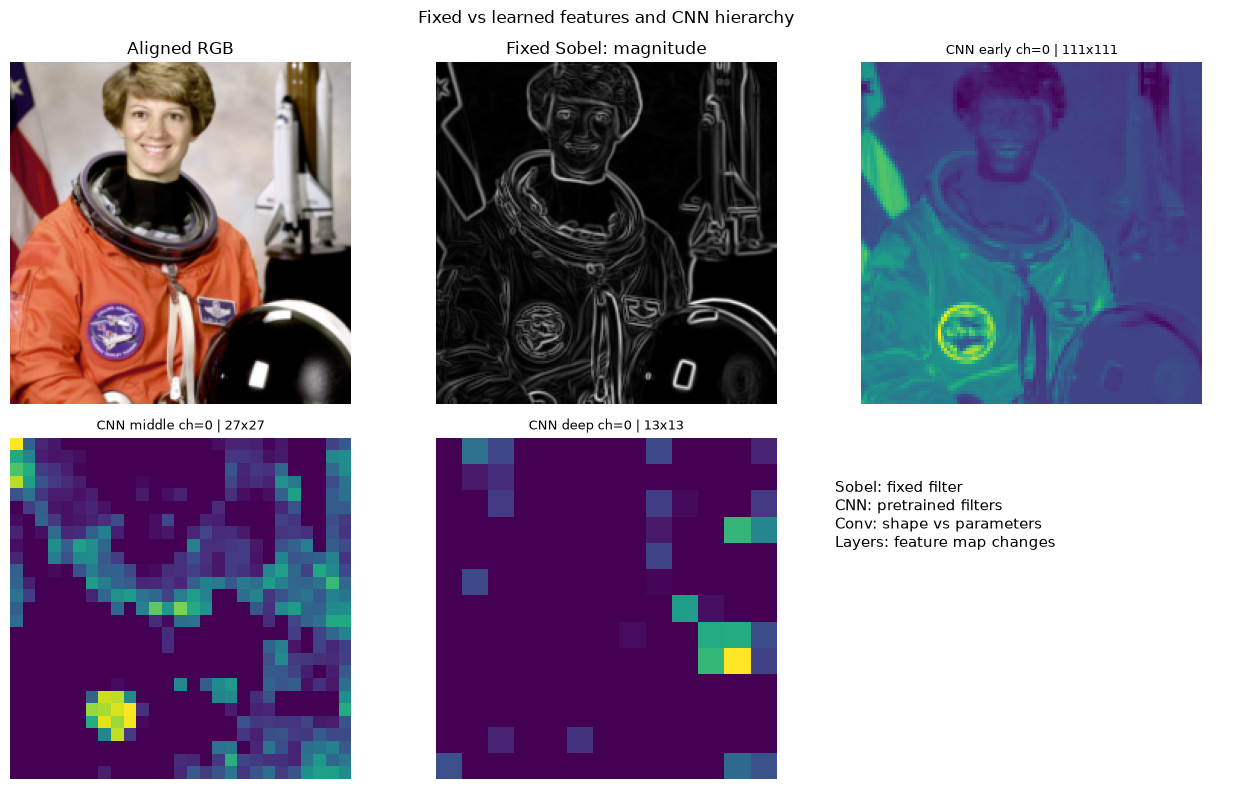

실습 완료: Sobel·CNN 비교 / Conv 출력 Shape / 계층별 Feature Map


In [21]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes[0, 0].imshow(aligned_rgb)
axes[0, 0].set_title("Aligned RGB")
axes[0, 1].imshow(sobel_mag_view, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Fixed Sobel: magnitude")
show_feature(axes[0, 2], feature_maps["early"], 0, "CNN early")
show_feature(axes[1, 0], feature_maps["middle"], 0, "CNN middle")
show_feature(axes[1, 1], feature_maps["deep"], 0, "CNN deep")
axes[1, 2].axis("off")
axes[1, 2].text(
    0.03, 0.88,
    "Sobel: fixed filter\n"
    "CNN: pretrained filters\n"
    "Conv: shape vs parameters\n"
    "Layers: feature map changes",
    va="top", fontsize=11,
)
for ax in (axes[0, 0], axes[0, 1]):
    ax.axis("off")
fig.suptitle("Fixed vs learned features and CNN hierarchy")
plt.tight_layout()
plt.show()

print("실습 완료: Sobel·CNN 비교 / Conv 출력 Shape / 계층별 Feature Map")